# Mixed Distributions Blog Analysis

This notebook accompanies the mixed-distributions blog article. It supplements [the public mixed-distributions demo](mixed_distributions.ipynb) with equal-cost comparisons between hierarchical mixture sampling and probability-weighted component integration, including numerical results and figures.

**Hierarchical Mixture** first selects a component according to its probability and then applies that component's transform. We use the current repository's `Mixture`: its first uniform coordinate is the selector $V$, the remaining coordinates are $U$, and the driver dimension is $d+1$ for $d$-dimensional observations. **Probability-Weighted Component Integration** instead estimates each component expectation and combines the estimates using the mixture probabilities.

For two components,

$$
\widehat I_{\rm hier}=\frac1N\sum_{i=1}^N f(T_{C(V_i)}(U_i)),
\qquad
\widehat I_{\rm comp}=p\widehat I_1+(1-p)\widehat I_2.
$$

Both methods have **$N$ total evaluations of the chosen function**: Hierarchical Mixture uses $N$ samples; component integration uses $N/2$ samples per component. For example, $N=1024$ means 1024 versus $512+512$ evaluations. The half-budget allocation does **not** change the mixture weights to $1/2,1/2$, and is not claimed to be an optimal allocation.

## 1. Imports and Reproducibility

Run from this repository or its `demos` directory with the Quasi-Monte Carlo Python (QMCPy) development environment. No downloads or external data are required. All convergence calculations use randomized quasi-Monte Carlo (QMC) sampling via `DigitalNetB2`, with 32 independent randomizations using linear matrix scrambling (LMS) and digital shift (DS), total budgets $2^6,\ldots,2^{15}$, and slopes fitted to the largest five budgets.

A full run takes about four minutes and writes four Portable Network Graphics (PNG) files to `demos/mixed_distributions_blog_outputs/`. The matching booktest executes every cell with smaller budgets and two mixture cases in memory, writing figures to a temporary directory; it does not replace the full-run results saved here. In Google Colaboratory (Colab), run the dependency cell first to install QMCPy from `develop`.

<!-- # colab-install-from-source -->

The means, covariances, parameter seeds, and hierarchical QMC seeds below reproduce the merged demo's choices. There is an intentional implementation difference: the demo's exploratory convergence code puts $V$ last and uses the originally generated dense factor $A$. Here the actual `Mixture` application programming interface (API) puts $V$ first, and both methods use `Gaussian`'s default principal component analysis (PCA) square root of the **same covariance** $AA^\mathsf{T}$. Thus the distributions and exact expectations agree, but the transformed QMC integrands and finite-budget errors need not reproduce the exploratory values. New fixed component-integration seeds are recorded explicitly.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/QMCSoftware/QMCSoftware/blob/develop/demos/mixed_distributions_blog_analysis.ipynb)

In [ ]:
# @title Execute this cell to install dependencies
try:
  import google.colab
  IN_COLAB = True
except ImportError:
  IN_COLAB = False
if IN_COLAB:
  import sys
  import os
  repo_root = "/content/QMCSoftware"
  notebook_dir = f"{repo_root}/demos"
  if not os.path.isdir(repo_root):
    !git clone -q --depth 1 --branch develop https://github.com/QMCSoftware/QMCSoftware {repo_root}
  !pip install -q -e {repo_root}
  os.chdir(notebook_dir)
  if notebook_dir not in sys.path:
    sys.path.insert(0, notebook_dir)


In [1]:
from pathlib import Path
from time import perf_counter
import sys

repo_root = Path.cwd().resolve()
if not (repo_root / "qmcpy").is_dir():
    repo_root = repo_root.parent
if not (repo_root / "qmcpy").is_dir():
    raise RuntimeError("Run this notebook from the repository or its demos directory.")
sys.path.insert(0, str(repo_root))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from IPython.display import display
from scipy.stats import norm

import qmcpy
from qmcpy import DigitalNetB2, Gaussian, Mixture

assert Path(qmcpy.__file__).resolve() == repo_root / "qmcpy" / "__init__.py"
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 8)
output_dir = repo_root / "demos" / "mixed_distributions_blog_outputs"
output_dir.mkdir(exist_ok=True)

sample_sizes = 2 ** np.arange(6, 16)
replications = 32
n_max = int(sample_sizes[-1])
fit = slice(-5, None)
method_names = ("Hierarchical Mixture", "Probability-Weighted Component Integration")
plot_labels = ("Hierarchical Mixture", "Probability-Weighted\nComponent Integration")
started_notebook = perf_counter()

assert np.all(sample_sizes // 2 + sample_sizes // 2 == sample_sizes)
print("QMCPy checkout:", qmcpy.__file__)
print("NumPy:", np.__version__, "SciPy:", scipy.__version__)
print("Total budgets:", sample_sizes)
print("Randomizations:", replications, "| slope-fit budgets:", sample_sizes[fit])

QMCPy checkout: C:\Users\Owner\.codex\visualizations\2026\08\29\01a04e5d-e21b-7ef1-bda1-771ee826f954\mixed-distribution-worktree\qmcpy\__init__.py
NumPy: 2.3.2 SciPy: 1.16.1
Total budgets: [   64   128   256   512  1024  2048  4096  8192 16384 32768]
Randomizations: 32 | slope-fit budgets: [ 2048  4096  8192 16384 32768]


## 2. Shared Helper Functions

For a Gaussian component, $E[X^\mathsf{T}X]=\mu^\mathsf{T}\mu+\operatorname{tr}(\Sigma)$ and, in one dimension (1D), $E[\cos(X)]=e^{-\sigma^2/2}\cos(\mu)$. For the nonlinear ten-dimensional (10D) example we retain the demo's analytical reference:

$$
E[e^{iX^\mathsf{T}X}]=\det(I-2i\Sigma)^{-1/2}
\exp\!\left(i\mu^\mathsf{T}(I-2i\Sigma)^{-1}\mu\right).
$$

Its real part is $E[\cos(X^\mathsf{T}X)]$. The implementation sums complex logarithms in the covariance eigenbasis, preserving the square-root branch continuously from zero rather than taking a potentially ambiguous square root of a complex determinant.

Each root mean square error (RMSE) is computed across the 32 independent randomized estimates, relative to its analytical expectation. Nested prefixes provide the different budgets; fitted log-log slopes are descriptive, finite-budget statistics. The same samples are reused for the two integrands, and replayed hierarchical seeds and shared component estimates keep both probabilities paired within each random case.

In [2]:
def replay_seed(seed):
    """Recreate a seed without advancing a shared SeedSequence."""
    if isinstance(seed, np.random.SeedSequence):
        return np.random.SeedSequence(
            seed.entropy, spawn_key=seed.spawn_key, pool_size=seed.pool_size
        )
    return np.random.SeedSequence(seed)


def gaussian_pair(dimension, parameter_seed):
    """Use the demo's mean/factor draws, in the same order."""
    rng = np.random.default_rng(replay_seed(parameter_seed))
    means = [rng.standard_normal(dimension) for _ in range(2)]
    factors = [
        rng.standard_normal((dimension, dimension)) / np.sqrt(dimension)
        for _ in range(2)
    ]
    covariances = [factor @ factor.T for factor in factors]
    return dict(means=means, factors=factors, covariances=covariances)


def gaussian_cos_squared_norm(mean, covariance):
    """Analytical E[cos(X.T @ X)], using the demo's eigenbasis formula."""
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    rotated_mean = eigenvectors.T @ mean
    factors = 1 - 2j * eigenvalues
    log_characteristic = (
        -0.5 * np.sum(np.log1p(-2j * eigenvalues))
        + 1j * np.sum(rotated_mean**2 / factors)
    )
    return float(np.exp(log_characteristic).real)


def exact_gaussian_expectations(mean, covariance, univariate=False):
    quadratic = mean @ mean + np.trace(covariance)
    cosine = (
        np.exp(-covariance[0, 0] / 2) * np.cos(mean[0])
        if univariate
        else gaussian_cos_squared_norm(mean, covariance)
    )
    return np.array([quadratic, cosine])


def exact_mixture_expectations(pair, probability, univariate=False):
    component_values = [
        exact_gaussian_expectations(mean, covariance, univariate)
        for mean, covariance in zip(pair["means"], pair["covariances"])
    ]
    return probability * component_values[0] + (1 - probability) * component_values[1]


def make_components(pair, seeds=(11, 13), n_rep=1):
    dimension = len(pair["means"][0])
    return [
        Gaussian(
            DigitalNetB2(dimension, seed=replay_seed(seed), replications=n_rep, randomize="LMS DS"),
            mean=mean,
            covariance=covariance,
            decomp_type="PCA",
        )
        for mean, covariance, seed in zip(pair["means"], pair["covariances"], seeds)
    ]


def prefix_estimates(samples, budgets, univariate=False):
    squared_norm = np.sum(samples**2, axis=-1)
    cosine = np.cos(samples[..., 0] if univariate else squared_norm)
    values = (squared_norm, cosine)
    # Axes: integrand, independent randomization, budget.
    return np.stack([
        np.stack([value[:, :int(n)].mean(axis=1) for n in budgets], axis=-1)
        for value in values
    ])


def hierarchical_estimates(pair, probability, seed, univariate=False):
    """Use the public Mixture sampler, not a hand-written selector transform."""
    dimension = len(pair["means"][0])
    mixture = Mixture(
        DigitalNetB2(
            dimension + 1, seed=replay_seed(seed), replications=replications,
            randomize="LMS DS",
        ),
        make_components(pair),
        [probability, 1 - probability],
    )
    assert mixture.d == dimension and mixture.discrete_distrib.d == dimension + 1
    # Independently verify the quadratic reference using public mixture moments.
    moment_check = np.sum(np.asarray(mixture.mean)**2) + np.trace(mixture.covariance)
    np.testing.assert_allclose(moment_check, exact_mixture_expectations(pair, probability)[0])
    samples = mixture(n_max)
    assert samples.shape == (replications, n_max, dimension)
    assert np.isfinite(samples).all()
    return prefix_estimates(samples, sample_sizes, univariate)


def component_estimates(pair, seeds, univariate=False):
    """Each component uses N/2 evaluations, not N, at total budget N."""
    components = make_components(pair, seeds, replications)
    estimates = []
    for component in components:
        samples = component(n_max // 2)
        assert samples.shape == (replications, n_max // 2, component.d)
        assert np.isfinite(samples).all()
        estimates.append(prefix_estimates(samples, sample_sizes // 2, univariate))
    return np.stack(estimates)


def rmse_across_replications(estimates, exact):
    return np.sqrt(np.mean((estimates - exact[:, None, None])**2, axis=1))


def empirical_slopes(curves):
    assert np.isfinite(curves).all() and np.all(curves > 0)
    fitted = np.polyfit(
        np.log(sample_sizes[fit]), np.log(curves[..., fit]).reshape(-1, 5).T, 1
    )[0]
    return fitted.reshape(curves.shape[:-1])


def compare_methods(pair, probabilities, hierarchical_seed, component_seeds, univariate=False):
    """Return paired curves: probability, integrand, method, budget."""
    separate = component_estimates(pair, component_seeds, univariate)
    curves = np.empty((len(probabilities), 2, 2, len(sample_sizes)))
    references = []
    for index, probability in enumerate(probabilities):
        exact = exact_mixture_expectations(pair, probability, univariate)
        hierarchical = hierarchical_estimates(pair, probability, hierarchical_seed, univariate)
        weighted_components = probability * separate[0] + (1 - probability) * separate[1]
        curves[index, :, 0] = rmse_across_replications(hierarchical, exact)
        curves[index, :, 1] = rmse_across_replications(weighted_components, exact)
        references.append(exact)
    assert np.isfinite(curves).all() and np.all(curves >= 0)
    return dict(rmse=curves, slopes=empirical_slopes(curves), exact=np.array(references))


def plot_comparison(ax, curves, title):
    for method, label in enumerate(plot_labels):
        ax.loglog(sample_sizes, curves[method], "o-", label=label, linewidth=1.8)
    ax.set(xlabel="Total function evaluations N", ylabel="RMSE", title=title)
    ax.legend(frameon=False, fontsize=9)


def export_figure(fig, name):
    path = output_dir / name
    fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    print("Exported:", path.name)

## 3. One-Dimensional Gaussian Mixture

We retain $0.3N(-2,0.7^2)+0.7N(2.5,1.1^2)$ and test $f(x)=x^2$ and $f(x)=\cos(x)$. The analytical quadratic expectation is $6.569$; the cosine reference is computed from the Gaussian identity above. Each component-integration estimate still has weights $0.3,0.7$, although it uses half of the total evaluations per component.

Exact E[X^2]: 6.568999999999999
Exact E[cos(X)]: -0.4039548336232325


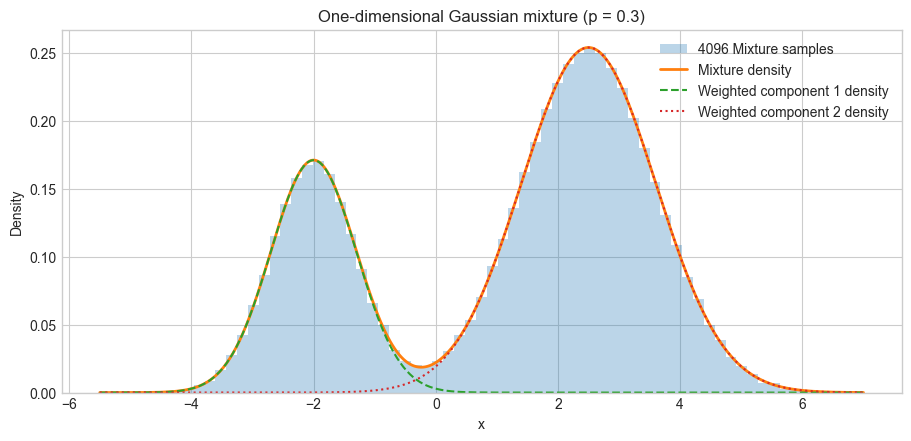

Exported: mixture_density_1d.png


In [3]:
mu1, sigma1 = -2.0, 0.7
mu2, sigma2 = 2.5, 1.1
p = 0.3
pair1 = dict(
    means=[np.array([mu1]), np.array([mu2])],
    factors=[np.array([[sigma1]]), np.array([[sigma2]])],
    covariances=[np.array([[sigma1**2]]), np.array([[sigma2**2]])],
)
exact1 = exact_mixture_expectations(pair1, p, univariate=True)
np.testing.assert_allclose(exact1[0], 6.569, rtol=0, atol=1e-12)
print("Exact E[X^2]:", exact1[0])
print("Exact E[cos(X)]:", exact1[1])

illustration = Mixture(
    DigitalNetB2(2, seed=20260914), make_components(pair1), [p, 1 - p]
)(4096)[:, 0]
grid = np.linspace(-5.5, 7, 700)
weighted_densities = (
    p * norm.pdf(grid, loc=mu1, scale=sigma1),
    (1 - p) * norm.pdf(grid, loc=mu2, scale=sigma2),
)
fig, ax = plt.subplots(figsize=(9, 4.3), layout="constrained")
ax.hist(illustration, bins=60, density=True, alpha=0.3, label="4096 Mixture samples")
ax.plot(grid, sum(weighted_densities), linewidth=2, label="Mixture density")
ax.plot(grid, weighted_densities[0], "--", label="Weighted component 1 density")
ax.plot(grid, weighted_densities[1], ":", label="Weighted component 2 density")
ax.set(xlabel="x", ylabel="Density", title="One-dimensional Gaussian mixture (p = 0.3)")
ax.legend(frameon=False)
export_figure(fig, "mixture_density_1d.png")

The two modes are associated with the components centered at $-2$ and $2.5$. Their integrated contributions are $0.3$ and $0.7$, not their peak heights. The histogram is one reusable sample set generated by `Mixture`; the lines are the analytical density and its probability-weighted components.

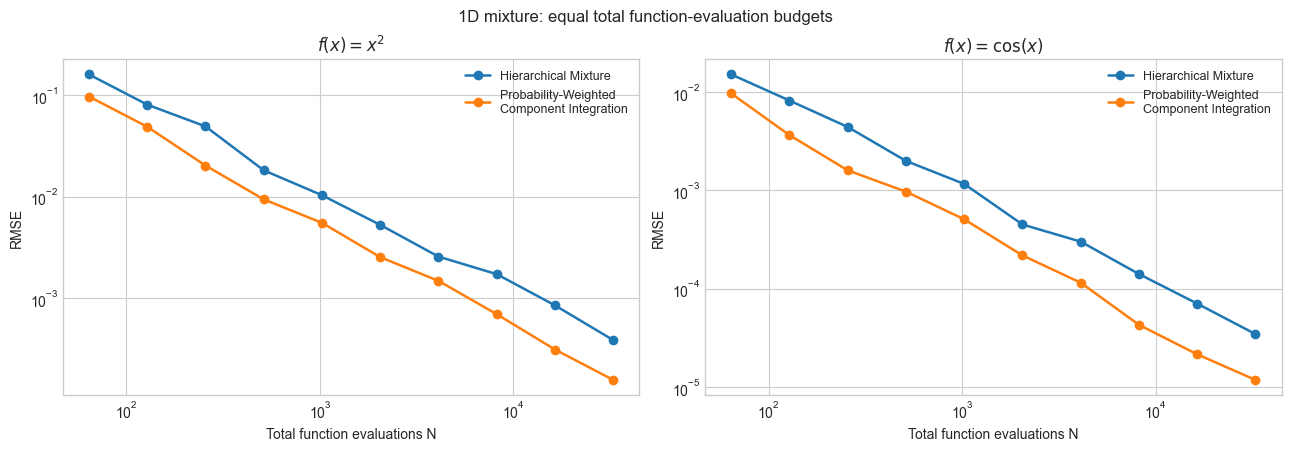

Exported: equal_cost_1d.png


In [4]:
result1 = compare_methods(
    pair1, [p], hierarchical_seed=20260922,
    component_seeds=(20260923, 20260924), univariate=True,
)
fig, axes = plt.subplots(1, 2, figsize=(12.8, 4.4), layout="constrained")
for index, (ax, title) in enumerate(zip(axes, [r"$f(x)=x^2$", r"$f(x)=\cos(x)$"])):
    plot_comparison(ax, result1["rmse"][0, index], title)
fig.suptitle("1D mixture: equal total function-evaluation budgets")
export_figure(fig, "equal_cost_1d.png")

These panels compare the methods at equal total evaluations, not equal points per component. The exact references are different for the two functions, but the distributions, budgets, randomization count, and slope-fitting range are unchanged. Generated slopes and final RMSEs are reported in Table A below.

## 4. Fixed Correlated Gaussian Mixtures

As in the demo, standard-normal means and dense factors $A_j/\sqrt d$ are generated with parameter seed 123 in the five-dimensional (5D) case and 321 in 10D; $\Sigma_j=A_jA_j^\mathsf{T}$. We test the quadratic function in 5D at $p=0.3$, in 10D at $p=0.3$ and $p=0.1$, and $\cos(x^\mathsf{T}x)$ on the same 10D components at $p=0.3$.

The cosine is smooth and bounded but oscillatory, unlike the quadratic moment. An independent million-sample ordinary-normal check validates its analytical reference; this check is **not** a third method in the QMC plots or an RMSE reference. The check retains the demo's original dense factors, while both QMC methods use the same PCA component transforms.

In [5]:
pair5 = gaussian_pair(5, 123)
pair10 = gaussian_pair(10, 321)
for pair in (pair5, pair10):
    for factor, covariance in zip(pair["factors"], pair["covariances"]):
        np.testing.assert_allclose(covariance, factor @ factor.T)
        assert np.any(np.abs(covariance - np.diag(np.diag(covariance))) > 1e-10)

# Preserve the demo's independent nonlinear-reference sanity check.
mc_rng = np.random.default_rng(854)
mc_n = 1_000_000
z_mc = mc_rng.standard_normal((mc_n, 10))
choose1_mc = mc_rng.random(mc_n) < 0.3
x_mc = np.empty_like(z_mc)
for index, selected in enumerate((choose1_mc, ~choose1_mc)):
    x_mc[selected] = z_mc[selected] @ pair10["factors"][index].T + pair10["means"][index]
values_mc = np.cos(np.sum(x_mc**2, axis=-1))
reference_cos10 = exact_mixture_expectations(pair10, 0.3)[1]
mc_estimate = values_mc.mean()
mc_standard_error = values_mc.std(ddof=1) / np.sqrt(mc_n)
mc_difference = abs(mc_estimate - reference_cos10)
if mc_difference > 5 * mc_standard_error:
    raise RuntimeError("Analytical cosine reference failed the independent MC sanity check.")
display(pd.DataFrame([dict(
    analytical_reference=reference_cos10, mc_estimate=mc_estimate,
    absolute_difference=mc_difference, mc_standard_error=mc_standard_error,
)]))
del z_mc, x_mc, choose1_mc, values_mc

,analytical_reference,mc_estimate,absolute_difference,mc_standard_error
0,-0.00395265,-0.0040768,0.00012415,0.00070818


,case,exact_expectation
0,"5D quadratic, p=0.3",6.56556862
1,"10D quadratic, p=0.3",12.59553367
2,"10D quadratic, p=0.1",10.45085478
3,"10D cosine quadratic, p=0.3",-0.00395265


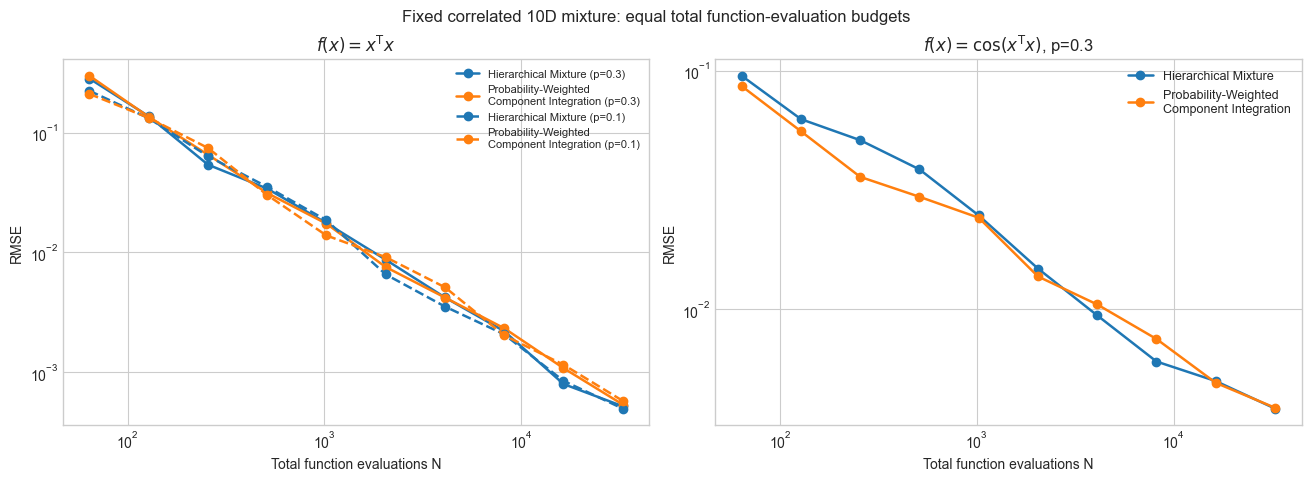

Exported: equal_cost_fixed_10d.png


In [6]:
# Fixed hierarchical seeds are those used in the merged demo.
result5 = compare_methods(pair5, [0.3], 124, (125, 126))
result10 = compare_methods(pair10, [0.3], 322, (323, 324))
result10_imbalanced = compare_methods(pair10, [0.1], 422, (423, 424))

fixed_rows = [
    ("5D quadratic, p=0.3", result5, 0),
    ("10D quadratic, p=0.3", result10, 0),
    ("10D quadratic, p=0.1", result10_imbalanced, 0),
    ("10D cosine quadratic, p=0.3", result10, 1),
]
display(pd.DataFrame([
    dict(case=name, exact_expectation=result["exact"][0, integrand])
    for name, result, integrand in fixed_rows
]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.7), layout="constrained")
for result, probability, line_style in (
    (result10, 0.3, "-"), (result10_imbalanced, 0.1, "--")
):
    # Restart the default color cycle: color identifies method, style identifies p.
    axes[0].set_prop_cycle(None)
    for method, label in enumerate(plot_labels):
        axes[0].loglog(
            sample_sizes, result["rmse"][0, 0, method],
            marker="o", linestyle=line_style, linewidth=1.8,
            label=f"{label} (p={probability})",
        )
axes[0].set(xlabel="Total function evaluations N", ylabel="RMSE", title=r"$f(x)=x^\mathsf{T}x$")
axes[0].legend(frameon=False, fontsize=8)
plot_comparison(axes[1], result10["rmse"][0, 1], r"$f(x)=\cos(x^\mathsf{T}x)$, p=0.3")
fig.suptitle("Fixed correlated 10D mixture: equal total function-evaluation budgets")
export_figure(fig, "equal_cost_fixed_10d.png")

The fixed cases are a stepping stone, not a population-level ranking. Table B retains the 5D evidence as well as the plotted 10D cases. Variation among individual cases motivates the paired 100-mixture study below.

## 5. One Hundred Random 10D Mixture Instances

We reproduce the merged demo's population: `SeedSequence(20260925).spawn(100)`, with each case spawning a parameter seed and a hierarchical QMC seed. Two component QMC seeds are spawned from a **replayed copy** of that QMC seed; doing so does not advance or alter the hierarchical seed. All cases use the same parameter-generation order and $AA^\mathsf{T}$ covariance construction as the fixed experiments.

Within a case, both methods use exactly the same component parameters. Both integrands reuse each method's samples; both probabilities reuse identical hierarchical uniform points through deterministic seed replay and the same component estimates. The original component factors and both reference expectations are computed once per case. Only compact RMSE/reference arrays are retained between cases.

The panels show median RMSE and the 25th–75th percentile **across mixture instances**, not confidence intervals. Slope quantiles summarize individual-case fits rather than a fit to the median RMSE curve.

In [7]:
n_cases100 = 100
p_values100 = (0.3, 0.1)
master_seed100 = 20260925
case_seeds100 = np.random.SeedSequence(master_seed100).spawn(n_cases100)
# Axes: case, probability, integrand, method, budget.
rmse_random = np.empty((n_cases100, 2, 2, 2, len(sample_sizes)))
slopes_random = np.empty((n_cases100, 2, 2, 2))
references_random = np.empty((n_cases100, 2, 2))
started_random = perf_counter()

for case_index, case_seed in enumerate(case_seeds100):
    parameter_seed, qmc_seed = replay_seed(case_seed).spawn(2)
    pair = gaussian_pair(10, parameter_seed)
    component_seeds = replay_seed(qmc_seed).spawn(2)
    result = compare_methods(pair, p_values100, qmc_seed, component_seeds)
    rmse_random[case_index] = result["rmse"]
    slopes_random[case_index] = result["slopes"]
    references_random[case_index] = result["exact"]
    if (case_index + 1) % 10 == 0:
        print(f"Completed {case_index + 1}/{n_cases100} cases", flush=True)
    del pair, result

elapsed_random = perf_counter() - started_random
rmse_quantiles_random = np.quantile(rmse_random, [0.25, 0.5, 0.75], axis=0)
slope_quantiles_random = np.quantile(slopes_random, [0.25, 0.5, 0.75], axis=0)
final_rmse_ratios = rmse_random[..., 0, -1] / rmse_random[..., 1, -1]
print(f"100-case calculation: {elapsed_random:.1f} seconds")

Completed 10/100 cases


Completed 20/100 cases


Completed 30/100 cases


Completed 40/100 cases


Completed 50/100 cases


...

Completed 70/100 cases


Completed 80/100 cases


Completed 90/100 cases


Completed 100/100 cases


100-case calculation: 198.0 seconds


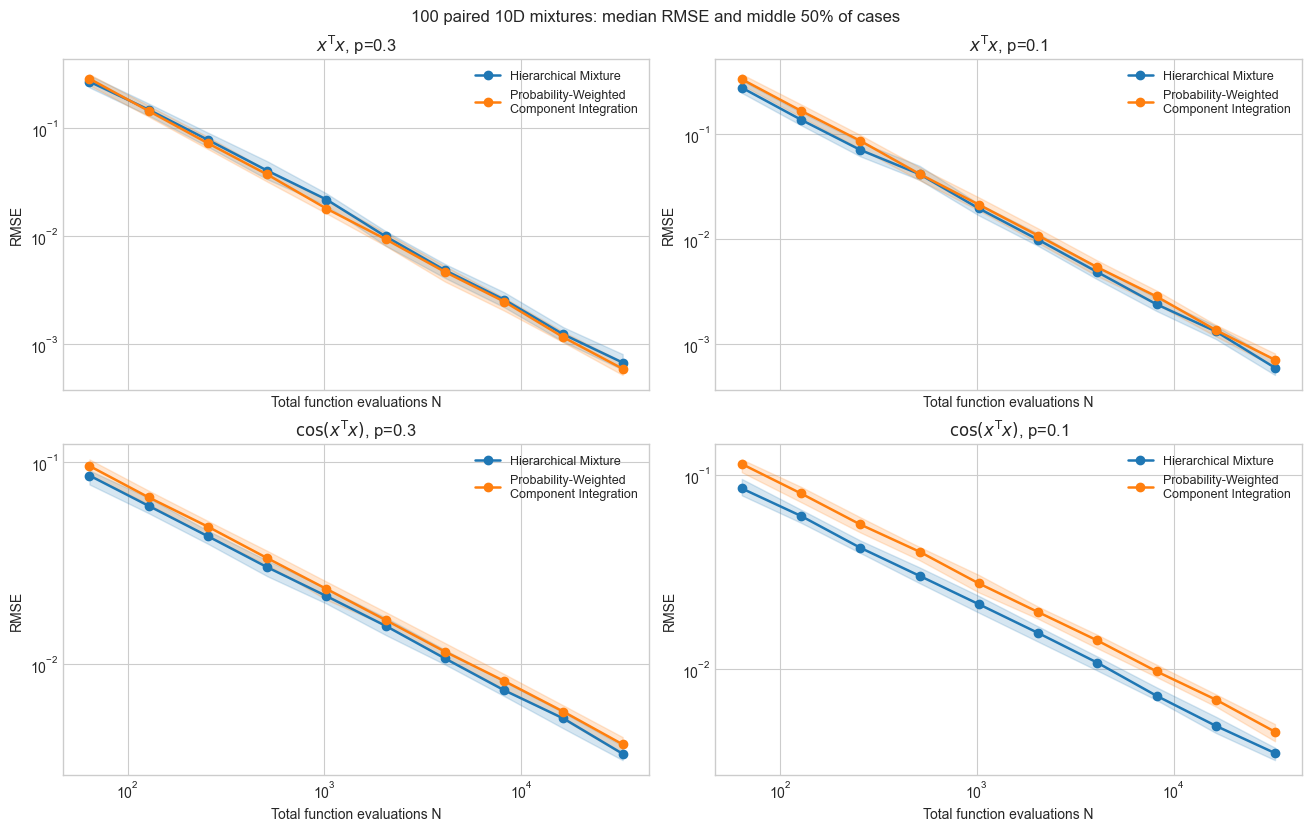

Exported: equal_cost_random_10d.png


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8.2), layout="constrained", sharex=True)
integrand_titles = (r"$x^\mathsf{T}x$", r"$\cos(x^\mathsf{T}x)$")
for integrand, title in enumerate(integrand_titles):
    for probability_index, probability in enumerate(p_values100):
        ax = axes[integrand, probability_index]
        for method, label in enumerate(plot_labels):
            lower, median, upper = rmse_quantiles_random[:, probability_index, integrand, method]
            line, = ax.loglog(sample_sizes, median, "o-", linewidth=1.8, label=label)
            ax.fill_between(sample_sizes, lower, upper, color=line.get_color(), alpha=0.18)
        ax.set(xlabel="Total function evaluations N", ylabel="RMSE", title=f"{title}, p={probability}")
        ax.legend(frameon=False, fontsize=9)
fig.suptitle("100 paired 10D mixtures: median RMSE and middle 50% of cases")
export_figure(fig, "equal_cost_random_10d.png")

## 6. Generated Blog Tables

Every entry below comes from the executed experiment arrays. Final RMSE means $N=32768$ **total** function evaluations per randomization, including both components for component integration. Table C reports medians across cases; all slope and RMSE quartiles are also available in `slope_quantiles_random` and `rmse_quantiles_random`.

The final-error ratio is calculated **within each paired case**, then summarized by its median. A ratio above one favors component integration for that statistic; below one favors hierarchical sampling. It is not the ratio of the two marginal medians.

In [9]:
def fixed_table_row(label, result, integrand):
    return {
        "case": label,
        "hierarchical slope": result["slopes"][0, integrand, 0],
        "component slope": result["slopes"][0, integrand, 1],
        "hierarchical final RMSE": result["rmse"][0, integrand, 0, -1],
        "component final RMSE": result["rmse"][0, integrand, 1, -1],
    }


table_a = pd.DataFrame([
    fixed_table_row(label, result1, index)
    for index, label in enumerate(("x^2", "cos(x)"))
]).rename(columns={"case": "integrand"})
table_b = pd.DataFrame([
    fixed_table_row(label, result, integrand)
    for label, result, integrand in fixed_rows
])
rows_c = []
for integrand, label in enumerate(("x^T x", "cos(x^T x)")):
    for probability_index, probability in enumerate(p_values100):
        rows_c.append({
            "integrand": label,
            "p": probability,
            "hierarchical median slope": slope_quantiles_random[1, probability_index, integrand, 0],
            "component median slope": slope_quantiles_random[1, probability_index, integrand, 1],
            "hierarchical median final RMSE": rmse_quantiles_random[1, probability_index, integrand, 0, -1],
            "component median final RMSE": rmse_quantiles_random[1, probability_index, integrand, 1, -1],
            "median paired final RMSE ratio H/C": np.median(final_rmse_ratios[:, probability_index, integrand]),
        })
table_c = pd.DataFrame(rows_c)

print("Table A — 1D")
display(table_a)
print("Table B — fixed higher-dimensional cases")
display(table_b)
print("Table C — 100 paired random 10D mixtures")
display(table_c)

for values in (
    rmse_random, slopes_random, references_random, final_rmse_ratios,
    rmse_quantiles_random, slope_quantiles_random,
):
    assert np.isfinite(values).all()
assert np.all(rmse_random >= 0)
for table in (table_a, table_b, table_c):
    assert np.isfinite(table.select_dtypes(include="number").to_numpy()).all()
expected_figures = (
    "mixture_density_1d.png", "equal_cost_1d.png",
    "equal_cost_fixed_10d.png", "equal_cost_random_10d.png",
)
assert all((output_dir / name).is_file() for name in expected_figures)
elapsed_notebook = perf_counter() - started_notebook
print(f"Notebook calculations: {elapsed_notebook:.1f} seconds")
print("Validated finite results, nonnegative RMSEs, equal cost, and all four PNG exports.")

Table A — 1D


,integrand,hierarchical slope,component slope,hierarchical final RMSE,component final RMSE
0,x^2,-0.91199417,-1.02637284,0.00038735,0.00015722
1,cos(x),-0.94987311,-1.08310743,0.00003447,0.00001179


Table B — fixed higher-dimensional cases


,case,hierarchical slope,component slope,hierarchical final RMSE,component final RMSE
0,"5D quadratic, p=0.3",-0.96055400,-1.04006854,0.00034906,0.00031918
1,"10D quadratic, p=0.3",-1.05307225,-0.95842653,0.00051815,0.00053577
2,"10D quadratic, p=0.1",-0.95044642,-1.01185763,0.00049548,0.00057509
3,"10D cosine quadratic, p=0.3",-0.48135522,-0.47473012,0.00382541,0.00385641


Table C — 100 paired random 10D mixtures


,integrand,p,hierarchical median slope,component median slope,hierarchical median final RMSE,component median final RMSE,median paired final RMSE ratio H/C
0,x^T x,0.3,-0.96724987,-0.98686848,0.00066864,0.00058650,1.12662488
1,x^T x,0.1,-0.99522484,-0.98368608,0.00059670,0.00071081,0.83291770
2,cos(x^T x),0.3,-0.52641012,-0.51776110,0.00360423,0.00401285,0.92258009
3,cos(x^T x),0.1,-0.50872464,-0.51206498,0.00368671,0.00474773,0.76682532


Notebook calculations: 208.0 seconds
Validated finite results, nonnegative RMSEs, equal cost, and all four PNG exports.


## 7. Interpretation

Hierarchical Mixture introduces a discontinuity at the component-selection threshold, but that discontinuity alone does not determine the observed performance. Component integration has lower final RMSE in the 1D examples and the fixed 5D quadratic case. Across the random 10D quadratic cases, it has a modest median advantage at $p=0.3$, but not at $p=0.1$ in this PCA-based comparison. For $\cos(x^\mathsf{T}x)$, both methods have empirical slopes near $-0.5$ and hierarchical sampling has smaller median final RMSE at both probabilities.

There is no universal numerical winner here. Performance depends on the integrand, dimension, mixture parameters, component transforms, and budget range. In particular, the earlier dense-factor, last-selector exploratory errors are not interchangeable with these public-API, PCA-based results: the covariance matrices and analytical expectations are unchanged, but the QMC mappings differ. The generated tables are the values to use for this implementation-based comparison.

Hierarchical Mixture directly produces a reusable sample set from the full mixture. Probability-Weighted Component Integration is especially natural when a particular expectation is the goal; it is not itself a direct mixture-sampling construction. All fitted slopes here are finite-budget numerical observations, not theoretical convergence rates or a theorem.